# BIOMASS tomogram provider

This notebook inspects both TOM L1D and L2A products without loading their multi-gigabyte measurement arrays, then opens a small L2A HV subset for visualization. Install the optional dependencies with `python -m pip install -e '.[tomogram,examples]'`.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

from tomo_canopy.providers import TomogramProvider
from tomo_canopy.types import DataLayer, GeometryType, Modality

## Inspect both products

`inspect()` reads only STAC and XML metadata. It is safe to use for inventory and product selection.

In [2]:
data_candidates = [Path("data/TOM"), Path("../data/TOM")]
TOM_DIRECTORY = next(
    (path for path in data_candidates if path.is_dir()), data_candidates[0]
)
provider = TomogramProvider()
products = [provider.inspect(path) for path in sorted(TOM_DIRECTORY.iterdir())]
for product in products:
    print(
        product.product_level, product.shape, product.polarizations,
        (product.vertical_minimum, product.vertical_maximum), product.bbox,
    )

L1D (2964, 1561, 81, 3) ('HH', 'VV', 'HV') (-60.0, 100.0) (-0.66627765760239, 10.86641062088875, 0.69262827679819, 11.69121173085234)
L2A (3262, 1980, 81, 3) ('HH', 'VV', 'HV') (-60.0, 100.0) (-0.66627765760239, 10.86641062088875, 0.69247234239761, 11.69099395422208)


## Open L1D in native SAR coordinates

L1D is not yet a geographic volume. Its axes remain relative azimuth time, slant-range time, relative height, and polarization.

In [3]:
l1d_product = next(product for product in products if product.product_level == "L1D")
l1d = provider.open(
    l1d_product.root, polarization="HV", height_range=(-20.0, 60.0),
    chunks="auto",
)
l1d

<xarray.Dataset> Size: 759MB
Dimensions:           (polarization: 1, z: 41, azimuth_time: 2964,
                       slant_range_time: 1561)
Coordinates:
  * polarization      (polarization) <U2 8B 'HV'
  * z                 (z) float64 328B -20.0 -18.0 -16.0 ... 56.0 58.0 60.0
  * azimuth_time      (azimuth_time) float64 24kB 0.0108 0.01767 ... 20.36 20.37
  * slant_range_time  (slant_range_time) float64 12kB 0.004948 ... 0.005154
Data variables:
    tomographic_cube  (polarization, z, azimuth_time, slant_range_time) float32 759MB dask.array<chunksize=(1, 14, 593, 313), meta=np.ndarray>
Attributes: (12/13)
    source:              /home/simon/Documents/science/GFZ/projects/biomass-h...
    product_root:        /home/simon/Documents/science/GFZ/projects/biomass-h...
    product_id:          BIO_TP_TOM_L1D_20251007T050300_20251022T050313_C_G__...
    product_level:       L1D
    modality:            tomogram
    geometry_type:       volume
    ...                  ...
    vertical_reference:  relative_tomographic_height
    vertical_units:      m
    stac_bbox:           (-0.66627765760239, 10.86641062088875, 0.69262827679...
    coordinate_space:    sar
    acquisition_start:   2025-10-07T05:03:00.188646Z
    acquisition_end:     2025-10-22T05:03:13.292892Z

## Open a bounded L2A geographic volume

The subset is centred on the product footprint and spans about 0.04° in each horizontal direction. Data is read only when the plots request values.

In [4]:
l2a_product = next(product for product in products if product.product_level == "L2A")
minimum_x, minimum_y, maximum_x, maximum_y = l2a_product.bbox
centre_x = (minimum_x + maximum_x) / 2
centre_y = (minimum_y + maximum_y) / 2
l2a = provider.open(
    l2a_product.root,
    polarization="HV",
    height_range=(-20.0, 60.0),
    bounds=(centre_x - 0.02, centre_y - 0.02, centre_x + 0.02, centre_y + 0.02),
    chunks="auto",
)
l2a

<xarray.Dataset> Size: 2MB
Dimensions:           (polarization: 1, z: 41, y: 96, x: 96)
Coordinates:
  * polarization      (polarization) <U2 8B 'HV'
  * z                 (z) float64 328B -20.0 -18.0 -16.0 ... 56.0 58.0 60.0
  * y                 (y) float64 768B 11.26 11.26 11.26 ... 11.3 11.3 11.3
  * x                 (x) float64 768B -0.006694 -0.006278 ... 0.03247 0.03289
Data variables:
    tomographic_cube  (polarization, z, y, x) float32 2MB dask.array<chunksize=(1, 14, 96, 96), meta=np.ndarray>
Attributes: (12/14)
    coordinate_normalization:  XML latitude/longitude fields swapped to match...
    source:                    /home/simon/Documents/science/GFZ/projects/bio...
    product_root:              /home/simon/Documents/science/GFZ/projects/bio...
    product_id:                BIO_TP_TOM_L2A_20251007T050300_20251022T050313...
    product_level:             L2A
    modality:                  tomogram
    ...                        ...
    vertical_reference:        relative_tomographic_height
    vertical_units:            m
    stac_bbox:                 (-0.66627765760239, 10.86641062088875, 0.69247...
    coordinate_space:          geographic
    acquisition_start:         2025-10-07T05:03:00.188646Z
    acquisition_end:           2025-10-22T05:03:13.292892Z

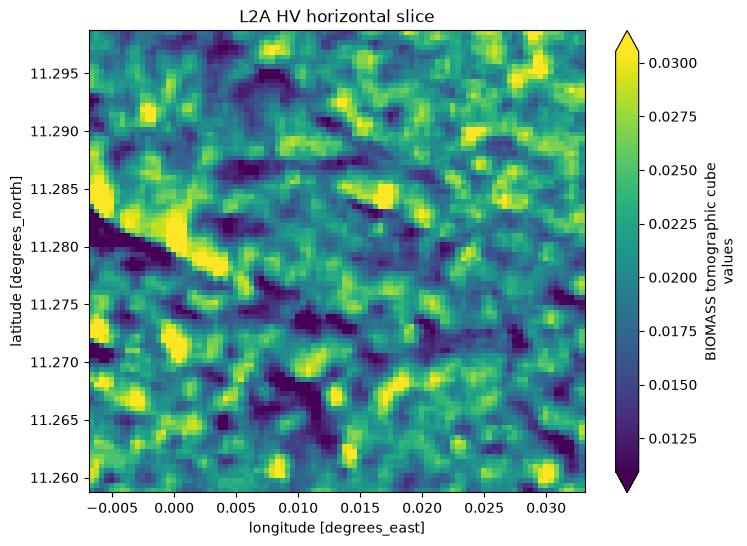

In [8]:
horizontal_slice = l2a.tomographic_cube.sel(
    polarization="HV", z=10.0, method="nearest"
).compute()
horizontal_slice.plot(
    
    x="x", y="y", robust=True, figsize=(8, 6),
)
plt.title("L2A HV horizontal slice")
plt.show()

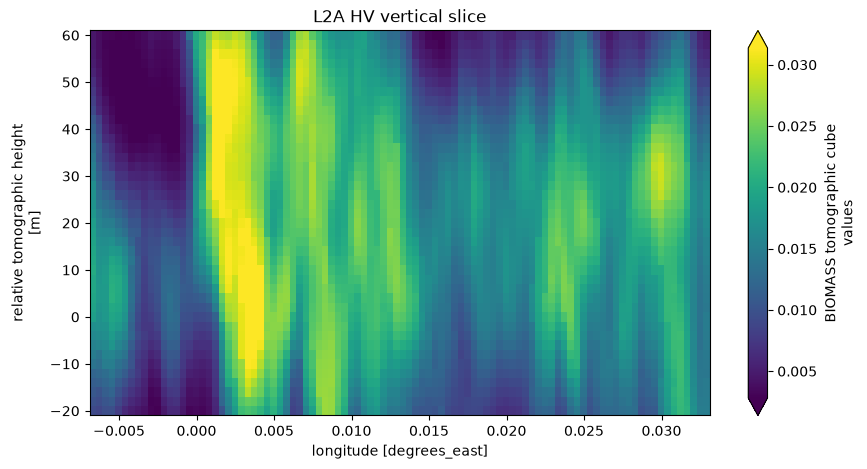

In [9]:
vertical_slice = l2a.tomographic_cube.sel(
    polarization="HV", y=centre_y, method="nearest"
).compute()
vertical_slice.plot(x="x", y="z", robust=True, figsize=(10, 5))
plt.title("L2A HV vertical slice")
plt.show()

## Wrap the geographic volume for the shared interface

The provider preserves the relative-height semantics in attributes. Reprojection and conversion to an absolute elevation grid belong in the tomogram processor.

In [10]:
tomogram_layer = DataLayer(
    name="biomass_tomogram", data=l2a,
    modality=Modality.TOMOGRAM, geometry=GeometryType.VOLUME,
)
tomogram_layer

DataLayer(name='biomass_tomogram', data=<xarray.Dataset> Size: 2MB
Dimensions:           (polarization: 1, z: 41, y: 96, x: 96)
Coordinates:
  * polarization      (polarization) <U2 8B 'HV'
  * z                 (z) float64 328B -20.0 -18.0 -16.0 ... 56.0 58.0 60.0
  * y                 (y) float64 768B 11.26 11.26 11.26 ... 11.3 11.3 11.3
  * x                 (x) float64 768B -0.006694 -0.006278 ... 0.03247 0.03289
Data variables:
    tomographic_cube  (polarization, z, y, x) float32 2MB dask.array<chunksize=(1, 14, 96, 96), meta=np.ndarray>
Attributes: (12/14)
    coordinate_normalization:  XML latitude/longitude fields swapped to match...
    source:                    /home/simon/Documents/science/GFZ/projects/bio...
    product_root:              /home/simon/Documents/science/GFZ/projects/bio...
    product_id:                BIO_TP_TOM_L2A_20251007T050300_20251022T050313...
    product_level:             L2A
    modality:                  tomogram
    ...                        